# The hydrogen molecule with VQE: ansatzes and Hamiltonians

## The problem

Two protons and two electrons. What is the lowest energy the electrons can have, as a function of the distance $R$ between the protons? That lowest energy is the **ground-state energy**, and its dependence on $R$ is what tells us the bond length and how strong the bond is. H$_2$ is the smallest molecule there is, so it is the standard first test of quantum chemistry on a quantum computer.

We find the ground state with the **variational quantum eigensolver (VQE)**: a classical optimizer tunes the angles of a circuit (the **ansatz**) to minimize the energy of the state it prepares. Two choices decide whether that works:

- the **Hamiltonian**: the same physics can be written for qubits in several ways (**qubit mappings**), with different numbers of qubits and different Pauli terms;
- the **ansatz**: the family of states the circuit can reach.

This notebook runs every combination in the same optimization loop and compares them.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | Build the H$_2$ Hamiltonian and map it to qubits | `ops.py` |
| 2. Encoding | Build the ansatzes | `encoding.py` |
| 3. Execution | Run the VQE loop for every pair | `execution.py` |
| 4. Analysis | Compare errors, cost and convergence | `analysis.py` |

The same steps run from the command line with `python hydrogen-molecule/main.py`. The code lives in `../scripts/hydrogen-molecule/` and is imported here, so the notebook and the command line cannot drift apart. Compared with the TSP example, the order is swapped: the Hamiltonian comes first because the encoding (which qubits, which reference state) depends on the mapping.

## Setup

By default this notebook runs on the Aer simulator with **exact energies** (no shot noise), so the differences you see come from the Hamiltonian and the ansatz alone. Set `shots` to a number such as `4096` to add sampling noise.

- `distance`: the H-H bond length in angstrom. The equilibrium value is about 0.735.
- `reps`: layers of the hardware-efficient ansatzes. `starts`: random starting points for the optimizer. `maxiter`: optimizer budget per start.
- `backend_name`: leave `None` for the simulator. A hardware run needs `shots > 0`, and it submits many jobs, so try one mapping and one ansatz first.

In [1]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image

# The H2 code lives in ../scripts/hydrogen-molecule.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/hydrogen-molecule").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

distance = 0.735  # angstrom
backend_name = None  # None = Aer simulator
reps = 2
starts = 3
maxiter = 300
shots = 0  # 0 = exact energies (simulator only)

## Step 1: The operator (the Hamiltonian)

### From molecule to 4 spin orbitals

We describe each electron with the lowest-energy orbitals available, the **minimal basis** (STO-3G): one $1s$ orbital per atom. Two orbitals combine into

- $\sigma_g$, the **bonding** orbital (electrons sit between the nuclei, low energy), and
- $\sigma_u$, the **antibonding** orbital (a node between the nuclei, high energy).

Each orbital holds a spin-up and a spin-down electron, so there are **4 spin orbitals**, in the order $[\sigma_g\uparrow, \sigma_u\uparrow, \sigma_g\downarrow, \sigma_u\downarrow]$. Two electrons fill them. The **Hartree-Fock (HF)** state puts one electron in each $\sigma_g$: the best answer if the electrons ignored each other's motion.

### Second quantization

The state of the electrons is written by saying which spin orbitals are occupied: $|n_0 n_1 n_2 n_3\rangle$ with $n_k\in\{0,1\}$. The Hamiltonian is

$$H = \sum_{pq} h_{pq}\, a^\dagger_p a_q + \tfrac12\sum_{pqrs}(pq|rs)\, a^\dagger_p a^\dagger_r a_s a_q + \frac1R,$$

where $a^\dagger_p$ and $a_p$ create and remove an electron in orbital $p$, $h_{pq}$ holds the kinetic energy and the attraction to the nuclei, $(pq|rs)$ is the electron-electron repulsion, and $1/R$ is the repulsion between the nuclei. The numbers $h_{pq}$ and $(pq|rs)$ are integrals over the Gaussians that make up the orbitals. `ops.py` computes them with a few lines of numpy, so no chemistry package is needed.

With 4 spin orbitals there are $2^4 = 16$ occupation patterns, so $H$ is a $16\times16$ matrix. That is small enough to diagonalize, which gives us the exact answer to compare with.

In [2]:
h, eri, e_nuc = ops.molecular_integrals(distance)
print(f"H-H distance {distance} A = {distance / ops.BOHR:.3f} bohr")
print(f"sigma_g one-electron energy  h_gg = {h[0, 0]:+.4f} Ha")
print(f"sigma_u one-electron energy  h_uu = {h[1, 1]:+.4f} Ha")
print(f"repulsion in sigma_g^2       (gg|gg) = {eri[0, 0, 0, 0]:.4f} Ha")
print(f"nuclear repulsion            1/R = {e_nuc:.4f} Ha")

exact = ops.exact_energies(distance)
print(f"\nHartree-Fock energy        {exact['hf']:.6f} Ha")
print(f"Exact (FCI) energy         {exact['fci']:.6f} Ha")
print(f"Correlation energy         {exact['fci'] - exact['hf']:+.6f} Ha")
print(f"Lowest over any electron number: {exact['fock_min']:.6f} Ha")

H-H distance 0.735 A = 1.389 bohr
sigma_g one-electron energy  h_gg = -1.2563 Ha
sigma_u one-electron energy  h_uu = -0.4719 Ha
repulsion in sigma_g^2       (gg|gg) = 0.6757 Ha
nuclear repulsion            1/R = 0.7200 Ha

Hartree-Fock energy        -1.116999 Ha
Exact (FCI) energy         -1.137306 Ha
Correlation energy         -0.020307 Ha
Lowest over any electron number: -1.137306 Ha


The gap between the two energies is the **correlation energy**, about 20 mHa. It is small next to the total energy, but chemistry lives at that scale: **chemical accuracy** is 1.6 mHa, the precision needed to predict reaction energies. A method that stops at Hartree-Fock is not good enough, and that is what VQE must improve on.

### From fermions to qubits: the mapping

A qubit register has $2^4=16$ basis states too, but we must decide which qubit state stands for which occupation pattern. The choice is the **qubit mapping**. Each mapping gives a different Pauli-string Hamiltonian with the **same eigenvalues**:

| Mapping | Qubit $k$ stores | Character |
|---|---|---|
| Jordan-Wigner (`jw`) | $n_k$ | simplest; qubit = orbital |
| Parity (`parity`) | $n_0+\dots+n_k \bmod 2$ | qubit holds the running parity |
| Bravyi-Kitaev (`bk`) | parity of a block of orbitals | balances the two above |
| Parity, reduced (`parity2`) | as parity, then 2 qubits dropped | **half the qubits** |

In the parity mapping, qubit 1 holds the parity of the spin-up electrons and qubit 3 the parity of all electrons. Both are conserved by $H$, and for H$_2$ (one up, one down electron) they are always 1 and 0. Two qubits are frozen, so we delete them: the **reduced** Hamiltonian acts on 2 qubits and has 5 Pauli terms instead of 15.

In [3]:
for mapping in ops.MAPPINGS:
    H = ops.build_hamiltonian(distance, mapping)
    weights = [sum(c != "I" for c in label) for label in H.paulis.to_labels()]
    energies = np.linalg.eigvalsh(H.to_matrix())
    print(
        f"{mapping:>8}: {H.num_qubits} qubits, {len(H):>2} Pauli terms, "
        f"max weight {max(weights)}, lowest energy {energies[0]:.6f} Ha"
    )

print("\nThe 2-qubit Hamiltonian in full:")
print(ops.build_hamiltonian(distance, "parity2"))

      jw: 4 qubits, 15 Pauli terms, max weight 4, lowest energy -1.137306 Ha
  parity: 4 qubits, 15 Pauli terms, max weight 4, lowest energy -1.137306 Ha
      bk: 4 qubits, 15 Pauli terms, max weight 4, lowest energy -1.137306 Ha
 parity2: 2 qubits,  5 Pauli terms, max weight 2, lowest energy -1.137306 Ha

The 2-qubit Hamiltonian in full:
SparsePauliOp(['II', 'IZ', 'XX', 'ZI', 'ZZ'],
              coeffs=[-0.33240425+0.j,  0.39793742+0.j,  0.18093119+0.j, -0.39793742+0.j,
 -0.0112801 +0.j])


## Stop and think: what is a "different Hamiltonian"?

1. **Same physics, same spectrum.** Every row prints the same lowest energy. A mapping is only a relabeling of basis states, so nothing about the molecule changes.
2. **What does change is the circuit cost and the landscape.** The number of qubits, the number of Pauli terms (each one is a measurement setting) and the weight of the terms (long strings need long chains of CX gates) all depend on the mapping. Step 3 shows that they also change how easily an optimizer finds the minimum.
3. **The reduced Hamiltonian uses a symmetry.** Particle number and spin are conserved, so the 16-dimensional space splits into blocks, and the ground state lives in one of them. Throwing away the other blocks removes qubits for free. That is not an approximation. The cost is that we must prepare the right sector ourselves.
4. **The 4-qubit forms contain unphysical states.** On 4 qubits, only 4 of the 16 states have one up and one down electron. The other 12 have the wrong number of electrons. An ansatz that does not respect electron number can wander into them.

## Step 2: Encoding and ansatzes

An ansatz $|\psi(\boldsymbol\theta)\rangle = U(\boldsymbol\theta)|\text{start}\rangle$ defines which states the optimizer can reach. By the **variational principle**, $\langle\psi|H|\psi\rangle \ge E_0$ for every state, so the lowest energy the optimizer finds is an upper bound on the truth. A better ansatz gets closer.

We compare five, ordered from most to least chemical knowledge:

| Ansatz | Idea | Angles (4 / 2 qubits) |
|---|---|---|
| `hf` | The Hartree-Fock state. No angles. The baseline. | 0 / 0 |
| `uccd` | HF plus the **double excitation**: both electrons hop $\sigma_g\to\sigma_u$. $\exp(\theta(T - T^\dagger))$. | 1 / 1 |
| `uccsd` | Same, plus single excitations. | 3 / 3 |
| `hea` | **Hardware-efficient**: layers of $R_Y$ and CX, starting from $|0\ldots0\rangle$. No chemistry. | 12 / 6 |
| `hea_hf` | The same, starting from the HF state. | 12 / 6 |

For H$_2$ in a minimal basis, the exact ground state is $\cos\phi\,|\text{HF}\rangle - \sin\phi\,|\text{doubly excited}\rangle$: HF mixed with one other determinant, and `uccd` produces exactly that family with one angle. The single excitations change the orbital's symmetry, which $H$ forbids, so `uccsd` adds angles that cannot help.

The UCC circuits are built from the fermionic generators in `ops.py`, so the same code works in every mapping. The first thing to check is that the HF reference state is prepared correctly: its energy must match the HF energy above in every mapping.

In [4]:
for mapping in ops.MAPPINGS:
    H = ops.build_hamiltonian(distance, mapping)
    ref = enc.hf_state(mapping)
    from qiskit.quantum_info import Statevector

    e = Statevector(ref).expectation_value(H).real
    print(f"{mapping:>8}: HF bitstring {ops.hf_bits(mapping)}, <H> = {e:.6f} Ha")

      jw: HF bitstring 0101, <H> = -1.116999 Ha
  parity: HF bitstring 0011, <H> = -1.116999 Ha
      bk: HF bitstring 0111, <H> = -1.116999 Ha
 parity2: HF bitstring 01, <H> = -1.116999 Ha


UCCD on the 2-qubit Hamiltonian:


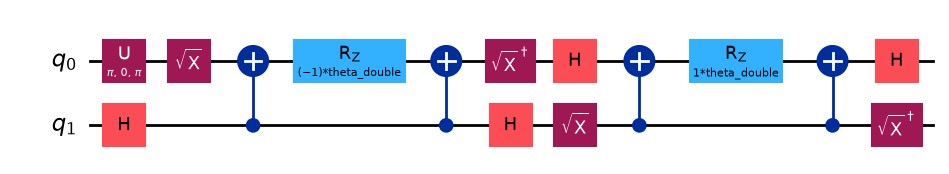

HEA on the 2-qubit Hamiltonian:


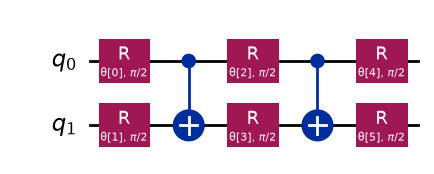

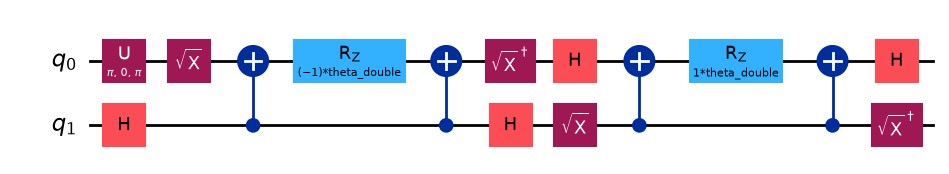

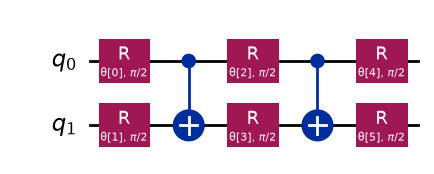

In [5]:
for name in ["uccd", "hea"]:
    print(enc.LABELS[name], "on the 2-qubit Hamiltonian:")
    display(enc.build_ansatz(name, "parity2", reps).decompose().draw("mpl", fold=-1))

In [6]:
# Circuit cost after compiling to {RZ, SX, X, CX}, per ansatz and mapping.
print(f"{'':>8}" + "".join(f"{a:>14}" for a in enc.ANSATZES))
for mapping in ops.MAPPINGS:
    cells = []
    for name in enc.ANSATZES:
        c = enc.build_ansatz(name, mapping, reps)
        depth, cx = enc.circuit_cost(c)
        cells.append(f"{cx:>3} CX, d={depth:<3}")
    print(f"{mapping:>8}" + "".join(f"{x:>14}" for x in cells))

                    hf          uccd         uccsd           hea        hea_hf


      jw   0 CX, d=1    34 CX, d=112  41 CX, d=126   6 CX, d=17    6 CX, d=19 
  parity   0 CX, d=1    27 CX, d=63   33 CX, d=88    6 CX, d=17    6 CX, d=19 
      bk   0 CX, d=1    27 CX, d=69   33 CX, d=86    6 CX, d=17    6 CX, d=19 
 parity2   0 CX, d=1     4 CX, d=17    4 CX, d=18    2 CX, d=14    2 CX, d=16 


## Stop and think: what did the encoding decide?

1. **UCC circuits are long, hardware-efficient circuits are short.** `uccd` needs tens of CX gates on 4 qubits, because each Pauli term of the excitation becomes a ladder of gates. `hea` has a fixed, shallow shape. On noisy hardware that difference matters, and it is why `hea` is popular despite its drawbacks.
2. **The mapping changes the UCC cost.** The same `uccd` circuit costs more in Jordan-Wigner than in parity or Bravyi-Kitaev, because the Pauli strings of the excitation are longer. In the reduced 2-qubit form it needs only a handful of gates.
3. **The ansatz must be able to express the answer.** `hf` cannot: it is a single determinant. `uccd` can, with one angle. `hea` can in principle (given enough layers), but nothing in its structure points toward it.
4. **`hea` does not know about electrons.** Its starting state $|0000\rangle$ is the empty molecule (zero electrons) in Jordan-Wigner. Nothing keeps it in the two-electron sector.

## Step 3: Execution

Each iteration of the VQE loop:

1. The classical optimizer (**COBYLA**) proposes angles $\boldsymbol\theta$.
2. The **Estimator** prepares $|\psi(\boldsymbol\theta)\rangle$ and returns $\langle H\rangle$.
3. The optimizer lowers $\langle H\rangle$ and repeats.

Every (mapping, ansatz) pair gets the same budget (`starts` random starting points, `maxiter` iterations each) and the same random seed, so that differences come from the pair and not from the settings. `hf` has no angles and is evaluated once. With exact energies the full table takes about a minute on the simulator.

In [7]:
data = execution.run(
    distance,
    ops.MAPPINGS,
    enc.ANSATZES,
    backend_name,
    reps=reps,
    starts=starts,
    shots=shots,
    maxiter=maxiter,
)
print(f"\nTotal time: {data['seconds']:.0f} s")

R = 0.735 A: exact (FCI) energy -1.137306 Ha, Hartree-Fock -1.116999 Ha
        jw      hf: error +2.03e-02 Ha (0 angles, 1 evaluations)


        jw    uccd: error +1.39e-13 Ha (1 angles, 102 evaluations)


        jw   uccsd: error +3.09e-13 Ha (3 angles, 206 evaluations)


        jw     hea: error +1.49e-02 Ha (12 angles, 900 evaluations)


        jw  hea_hf: error +1.55e-02 Ha (12 angles, 900 evaluations)
    parity      hf: error +2.03e-02 Ha (0 angles, 1 evaluations)


    parity    uccd: error +1.42e-13 Ha (1 angles, 103 evaluations)


... (7 outputs left out)

   parity2    uccd: error +1.43e-13 Ha (1 angles, 103 evaluations)


   parity2   uccsd: error +1.89e-13 Ha (3 angles, 201 evaluations)


   parity2     hea: error +1.07e-14 Ha (6 angles, 314 evaluations)


   parity2  hea_hf: error +6.22e-14 Ha (6 angles, 360 evaluations)

Total time: 30 s


## Step 4: Analysis

Each row is one pair. The **error** is the energy found minus the exact energy, so it is never negative (except for shot noise). `*` marks results within chemical accuracy. Then two views: convergence (error of the best restart against evaluations, one panel per mapping) and the final errors.


H2 at R = 0.735 A on aer_simulator, exact energies
Exact (FCI) energy:  -1.137306 Ha
Hartree-Fock energy: -1.116999 Ha
Correlation energy:  -0.020307 Ha

 mapping  ansatz qubits terms angles   CX depth  evals  error (mHa)
      jw      hf      4    15      0    0     1      1     20.3070 
      jw    uccd      4    15      1   34   112    102      0.0000*
      jw   uccsd      4    15      3   41   126    206      0.0000*
      jw     hea      4    15     12    6    17    900     14.9019 
      jw  hea_hf      4    15     12    6    19    900     15.4933 
  parity      hf      4    15      0    0     1      1     20.3070 
  parity    uccd      4    15      1   27    63    103      0.0000*
  parity   uccsd      4    15      3   33    88    204      0.0000*
  parity     hea      4    15     12    6    17    900      0.0019*
  parity  hea_hf      4    15     12    6    19    900      0.2049*
      bk      hf      4    15      0    0     1      1     20.3070 
      bk    uccd      4    15


Saved /tmp/h2_result.png


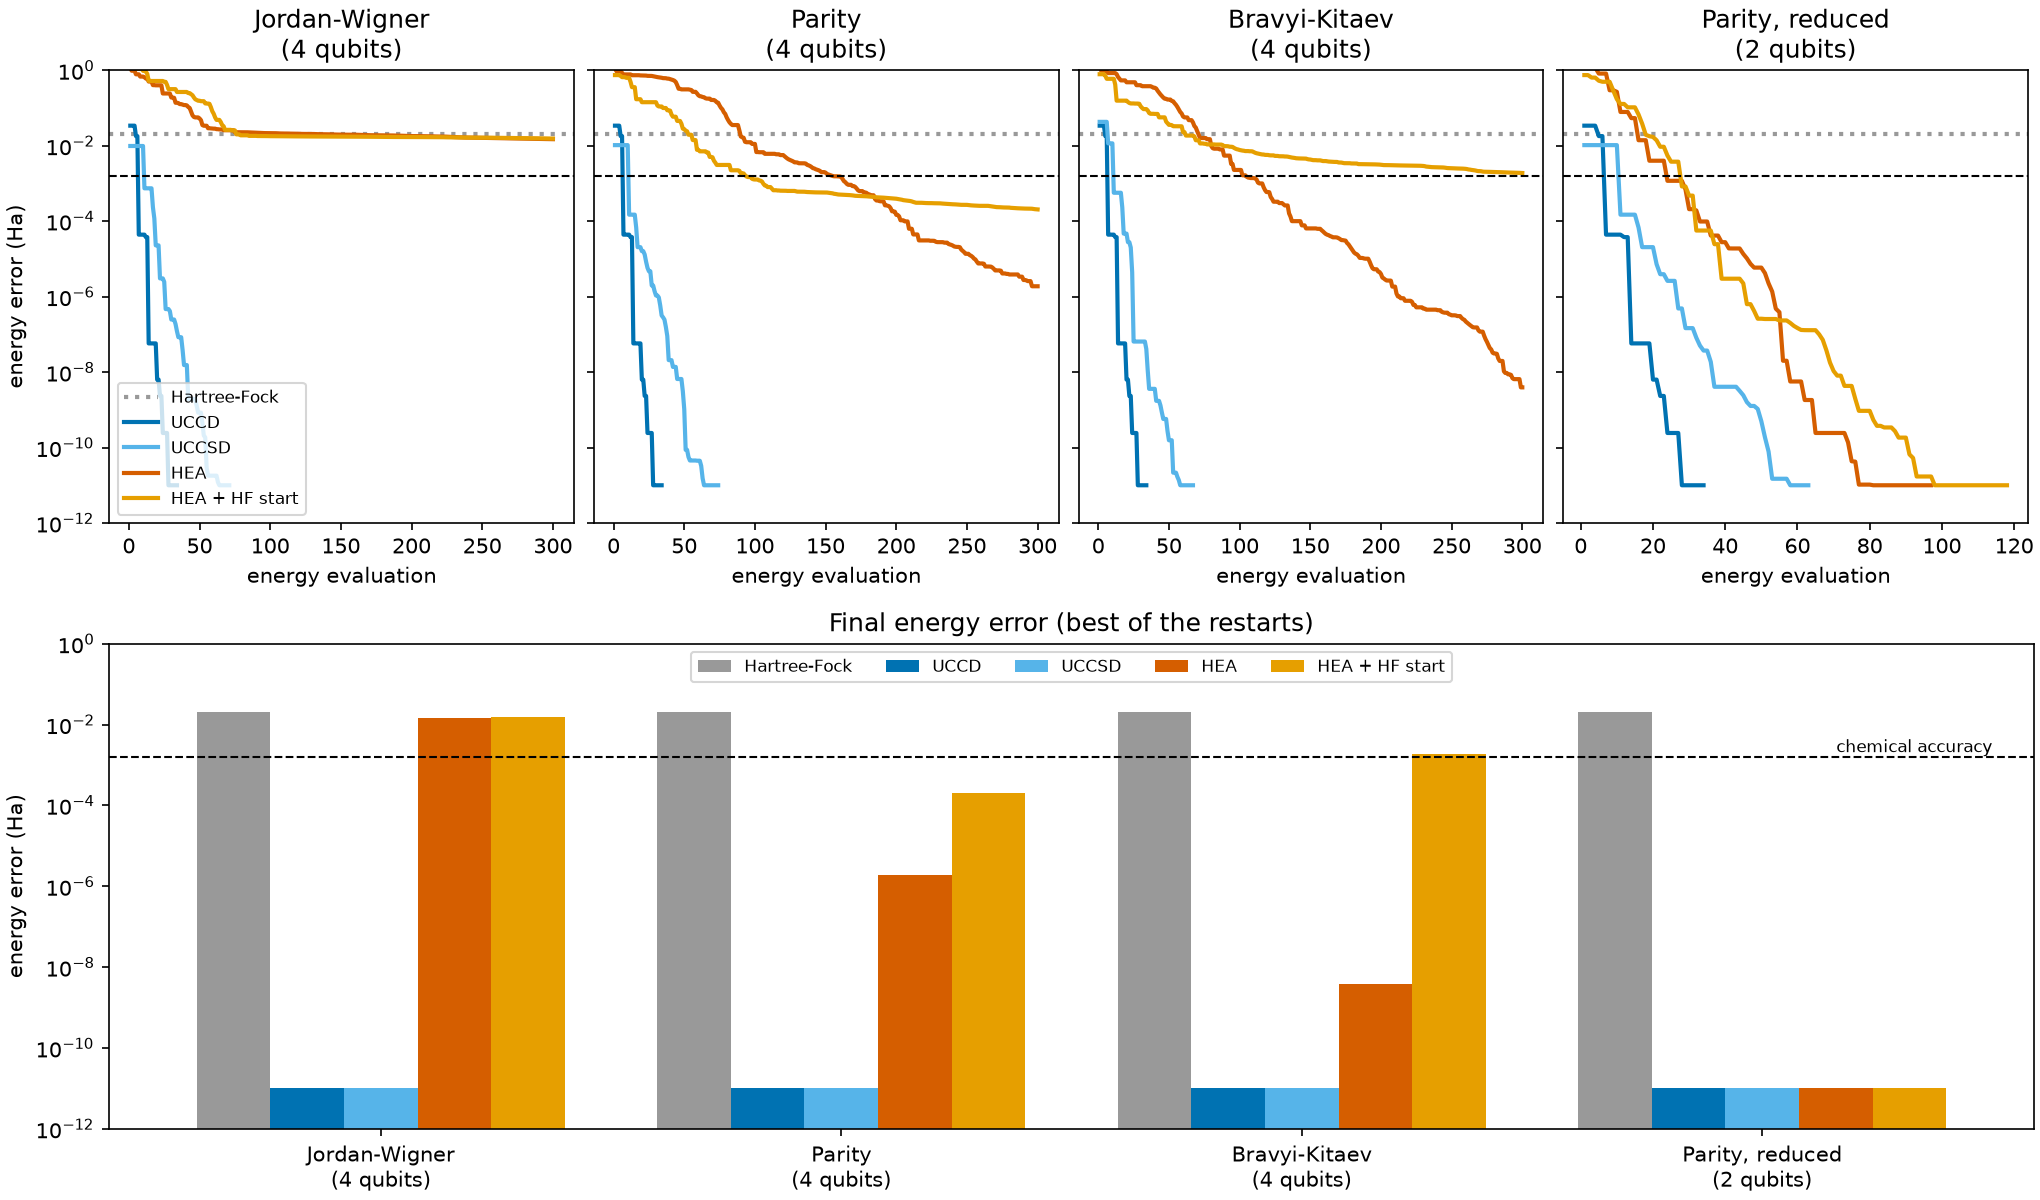

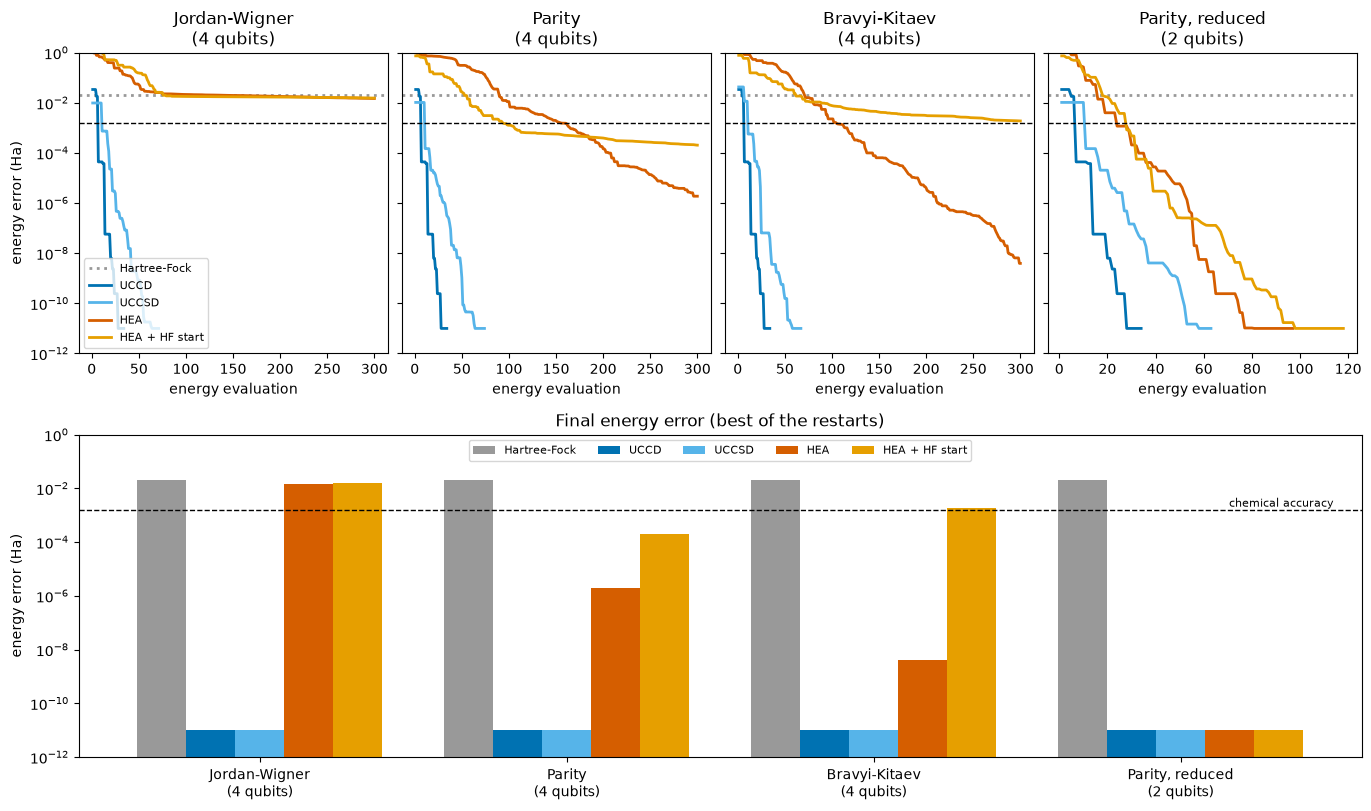

In [8]:
out = Path(tempfile.gettempdir()) / "h2_result.png"
analysis.analyze(data, out)
Image(out)

## Reading the results

- **`hf` (gray)** sits at the correlation energy, about 20 mHa, in every mapping. It never improves because it has no angles.
- **`uccd` and `uccsd` (blues)** reach the exact energy in every mapping, in about a hundred evaluations. The chemistry-aware circuit finds the answer from any start, and the mapping changes only the circuit cost. `uccsd` takes longer for no gain: the extra angles are dead weight.
- **`hea` and `hea_hf` (oranges)** depend strongly on the Hamiltonian. On the **reduced 2-qubit** Hamiltonian they match `uccd` (the 4-dimensional space has nowhere to go wrong). On the **4-qubit** forms the results differ from mapping to mapping and are often far from converged: the optimizer is searching all 16 states, mostly with the wrong electron number, so the landscape is large and flat, and the budget runs out. Which mapping happens to work for which start is not a property of the mapping, so rerun with another `seed` to see the pattern change. What does not change is that the 2-qubit form is reliably easy.

**Lesson:** the Hamiltonian and the ansatz are chosen together. A symmetry-aware Hamiltonian lets a generic ansatz succeed. A problem-aware ansatz succeeds with any Hamiltonian, at the price of a deeper circuit.

## Stretching the bond

At the equilibrium distance HF is only 20 mHa off. As the bond stretches, the molecule becomes two separate hydrogen atoms, and a single determinant describes that badly: HF puts equal weight on "both electrons on the same atom", which is wrong. The correlation energy grows, and a variational method has to capture it. We scan $R$ with the 2-qubit Hamiltonian and three ansatzes, and compare with the exact curve.

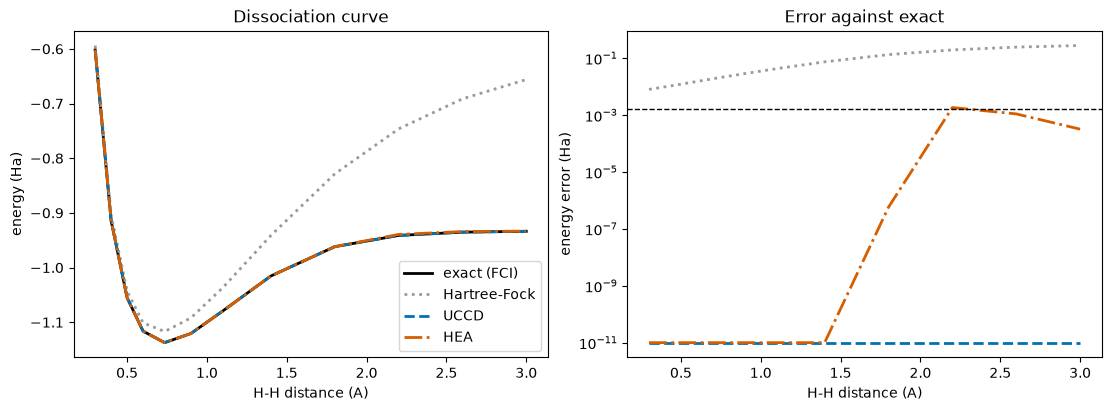

Exact minimum: -1.1373 Ha at R = 0.735 A


In [9]:
backend, estimator, session = execution.get_primitives(backend_name)
scan = [0.3, 0.4, 0.5, 0.6, 0.735, 0.9, 1.1, 1.4, 1.8, 2.2, 2.6, 3.0]
curves = {"exact": [], "hf": [], "uccd": [], "hea": []}
for R in scan:
    curves["exact"].append(ops.exact_energies(R)["fci"])
    for name in ("hf", "uccd", "hea"):
        rec = execution.optimize(
            R, "parity2", name, estimator, backend, reps, starts=2, shots=shots, maxiter=200
        )
        curves[name].append(rec["energy"])
if session is not None:
    session.close()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
style = {"exact": ("black", "-"), "hf": ("#999999", ":"), "uccd": ("#0072B2", "--"), "hea": ("#D55E00", "-.")}
for k, (color, ls) in style.items():
    label = "exact (FCI)" if k == "exact" else enc.LABELS[k]
    ax1.plot(scan, curves[k], color=color, ls=ls, lw=2, label=label)
    if k != "exact":
        err = np.maximum(np.array(curves[k]) - np.array(curves["exact"]), 1e-11)
        ax2.plot(scan, err, color=color, ls=ls, lw=2, label=label)
ax1.set(xlabel="H-H distance (A)", ylabel="energy (Ha)", title="Dissociation curve")
ax1.legend()
ax2.axhline(analysis.CHEMICAL_ACCURACY, color="black", ls="--", lw=1)
ax2.set(xlabel="H-H distance (A)", ylabel="energy error (Ha)", yscale="log", title="Error against exact")
plt.show()

i = int(np.argmin(curves["exact"]))
print(f"Exact minimum: {curves['exact'][i]:.4f} Ha at R = {scan[i]} A")

## Stop and think: what did the scan show?

1. **HF fails when the bond breaks.** Its error grows from 20 mHa to hundreds of mHa and its curve does not flatten out at the energy of two separate atoms ($-0.93$ Ha here). This is the textbook failure of a single determinant, and the reason correlated methods exist.
2. **`uccd` stays exact at every distance.** Its one angle tunes the mixture between the two determinants, from nearly pure HF at equilibrium toward an equal mixture as the bond stretches. The same circuit shape works everywhere, only the angle changes.
3. **The ansatz is judged on the hardest problem.** Near equilibrium even a weak ansatz does acceptably well. Away from it, differences show up. A benchmark at one geometry can hide them.
4. **Everything here is noiseless and exact.** Set `shots = 4096` and rerun Step 3: the optimizer now sees noisy energies and cannot resolve errors below roughly $1/\sqrt{\text{shots}}$, which is above chemical accuracy. Getting below it needs many more shots (and many more Pauli terms to measure), and noise from gates grows with circuit depth. Then the shallow `hea` and the deep `uccd` trade places.

## What to try next

1. Change `seed` in Step 3 (add `seed=2` to `execution.run`) and see which 4-qubit `hea` runs converge. Raise `maxiter` or `starts`: does the Hamiltonian ranking change?
2. Set `reps = 1` or `reps = 4`. How does the number of angles trade against reliability on 2 and 4 qubits?
3. Set `shots = 1000` and look at the final error. Which ansatzes survive sampling noise?
4. Run only a subset from the command line, for example `python hydrogen-molecule/main.py --mappings jw parity2 --ansatzes uccd hea --distance 2.0`.
5. Compute the bond length from the scan: where is the minimum? Refine the grid near it. The experimental value is 0.741 A.
6. Add an ansatz of your own to `encoding.py`, for example a single $R_Y$ on one qubit of the 2-qubit Hamiltonian followed by a CX. Is that enough to reach the exact energy?
7. The same recipe (build $H$, choose an ansatz, optimize) works for any molecule, but the number of qubits grows quickly. Compare the search over bitstrings in the TSP notebook with the search over states here: what plays the role of the "penalty" in each?